# Rare events, importance sampling and exact hypothesis tests

A simulation with no observed rare events needs a better estimator, not a claim that the event is impossible. Log probabilities preserve precision and exact binomial answers provide independent checks.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.statistics import rare_event, neyman_pearson

result = rare_event(500, 0.1, 0.3, 10000, 41)
print(
    "Naive hits",
    result["naive_hits"],
    "exact log probability",
    result["log_exact_probability"],
    "IS log probability",
    result["log_is_probability"],
    "relative standard error",
    result["relative_standard_error"],
)
assert (
    result["type_lower_log_probability"]
    <= result["log_exact_probability"]
    <= result["type_union_upper_log_probability"]
)

Naive hits 0 exact log probability -79.78166751366233 IS log probability -79.87923501024353 relative standard error 0.039103683933949945


**Recorded configuration**

{
  "family": "statistics",
  "id": "rare_event_500",
  "task": "rare_events",
  "blocklength": 500,
  "probability": 0.1,
  "threshold": 0.3,
  "trials": 10000
}
{
  "naive_hits": 0,
  "trials": 10000,
  "log_exact_probability": -79.78166751366233,
  "log_is_probability": -79.87923501024353,
  "relative_standard_error": 0.039103683933949945,
  "observed_exponent_bits": 0.2302012321516255,
  "sanov_exponent_bits": 0.22168969464705088,
  "type_lower_log_probability": -83.04839950298413,
  "type_union_upper_log_probability": -70.6151873008144,
  "scope": "IID binomial draws under a tilted Bernoulli proposal; likelihood weights restore the original law. Confidence uncertainty is Monte Carlo uncertainty, not a proof of a tail bound."
}


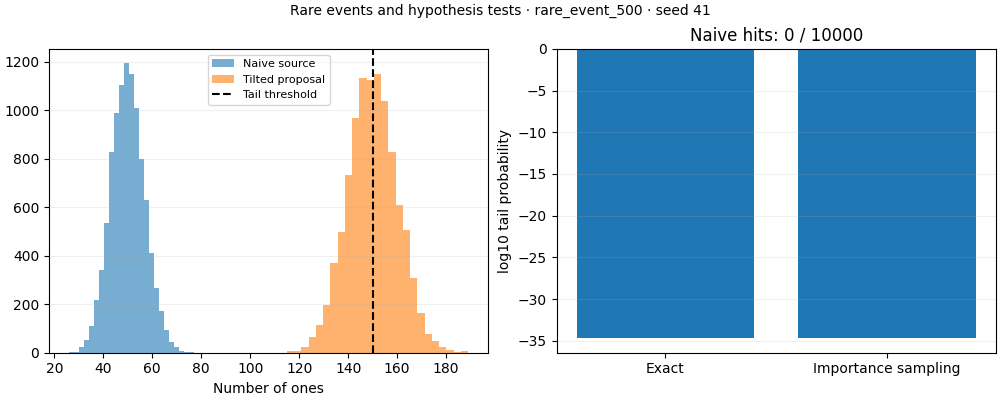

In [3]:
record, path = query("statistics", task="rare_events", blocklength=500)[0]
measured(record)
preview(record)

Neyman–Pearson testing randomizes at the binomial threshold to attain the false-alarm budget exactly. Stein’s exponent concerns asymptotic decay of missed detections, rather than an exact finite-block equality.

In [4]:
result = neyman_pearson(64, 0.1, 0.3, 0.05)
print(result)
assert np.isclose(result["false_alarm"], 0.05)

{'threshold': 11, 'boundary_randomization': 0.943883553164177, 'false_alarm': 0.05, 'log_miss_probability': -4.984141635920513, 'miss_exponent_bits': 0.11235306908173015, 'stein_limit_bits': 0.16781682137412188}


In [5]:
records = sorted(
    query("statistics", task="hypothesis_test"), key=lambda rp: rp[0]["config"]["blocklength"]
)
plt.plot(
    [r["config"]["blocklength"] for r, _ in records],
    [r["metrics"]["miss_exponent_bits"] for r, _ in records],
    "o-",
    label="Finite miss exponent",
)
plt.axhline(records[0][0]["metrics"]["stein_limit_bits"], ls="--", label="Stein limit")
plt.xscale("log")
plt.xlabel("Blocklength")
plt.ylabel("bits/source symbol")
plt.legend()
plt.show()